## Cultural attraction

When people reproduce a cultural pattern, they may transform it towards a familiar prototype. Can repeated reconstruction make initially different traditions resemble one another?

Imagine learning a decorative bead pattern by looking briefly at a teacher's example, then making a new one from memory. The learner track only the propotion of dark beards, not their arrangement. Every learner has different type of preferences: only dark, only light, or balanced. This preference is the model's proposed attraction direction.

We adapt the Bayesian learning mechanism in [Alex Mesoudi's book, Chapter 16](https://amesoudi-abmtutorial.share.connect.posit.cloud/model16.html). Each learner reconstructs a pattern from limited evidence and a shared prior. We compare initially all-light, balanced, and all-dark patterns.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import beta, binom, betabinom

sns.set_theme(context="paper", style="ticks", font_scale=1.1,
              rc={"axes.spines.top": False, "axes.spines.right": False})

## 1. Learn from one pattern

The model has two learning parameters:

| Parameter | Meaning |
|---|---|
| `n` | Number of observations: beads seen and produced by each learner. Initially 10. |
| `alpha` ($\alpha$) | Regularisation parameter. The prior is $\mathrm{Beta}(\alpha,\alpha)$, so both Beta shape parameters have this value. Initially 5. |

- `alpha < 1`: favours almost single-colour patterns, with `theta` near 0 or 1.
- `alpha = 1`: flat prior; all `theta` values are equally likely.
- `alpha > 1`: favours balanced mixtures, with `theta` near 0.5.

| Variable | Meaning |
|---|---|
| `k` | Dark beads in the input. |
| `theta` ($\theta$) | Probability that a bead is dark; this is what the learner infers. |
| `p` | Hypothesis space. |
| `prior` | Prior weights on the grid, normalised to sum to 1. |
| `lik` | Probability of seeing `k` dark beads out of `n`, for each candidate value in `p`. |
| `post` | Posterior weights after seeing the input. |

First calculate `lik` using the binomial distribution. Then multiply by `prior` and divide by the sum:

$$\text{post} = \frac{\text{prior}\times\text{lik}}{\sum(\text{prior}\times\text{lik})}.$$

This first calculation shows Bayes' rule explicitly on a grid. Compare the input proportion (0.9), the prior, and the posterior.

In [ ]:
def bayesian_update(k, n, p, prior):
    lik = binom.pmf(k, n, p)
    post = prior * lik
    post = post / post.sum()
    return post

In [67]:
n = 10
k = 1
alpha = 1
p = np.linspace(0.001, 0.999, 101)
prior = beta.pdf(p, alpha, alpha)
prior = prior / prior.sum()
lik = binom.pmf(k, n, p)
post = bayesian_update(k, n, p, prior)

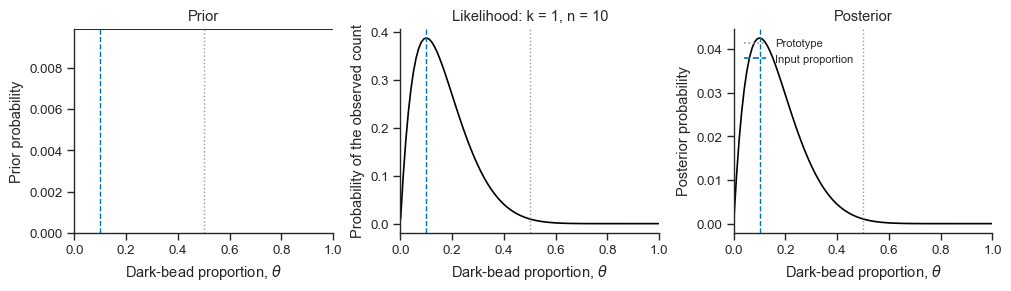

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), constrained_layout=True)
axes[0].plot(p, prior, color="black")
axes[1].plot(p, lik, color="black")
axes[2].plot(p, post, color="black")
for ax, title in zip(axes, ["Prior", f"Likelihood: k = {k}, n = {n}", "Posterior"]):
    ax.axvline(0.5, color="0.6", linestyle=":", linewidth=1)
    ax.axvline(k / n, color="#0072B2", linestyle="--", linewidth=1)
    ax.set(title=title, xlabel=r"Dark-bead proportion, $\theta$", xlim=(0, 1))
axes[0].set_ylabel("Prior probability")
axes[1].set_ylabel("Probability of the observed count")
axes[2].set_ylabel("Posterior probability")
axes[2].plot([], [], color="0.6", linestyle=":", label="Prototype")
axes[2].plot([], [], color="#0072B2", linestyle="--", label="Input proportion")
axes[0].set_ylim(bottom=0)
axes[2].legend(frameon=False, fontsize=8, loc="upper left")
plt.show()

### Switch to the equivalent conjugate posterior

From this point on, we use Mesoudi's conjugate shortcut. A Beta prior with a binomial likelihood gives an exact Beta posterior:

$$\mathrm{Beta}(\alpha,\alpha)\quad\longrightarrow\quad
\mathrm{Beta}(k+\alpha,\ n-k+\alpha).$$

This is the same Bayesian update as the multiplication above, calculated analytically. We now sample `theta` directly from this continuous posterior, rather than from the plotting grid. The chains use this exact shortcut too.

In [69]:
rng = np.random.default_rng(7)
theta = rng.beta(k + alpha, n - k + alpha)
k_next = rng.binomial(n, theta)
print(f"Input: {k}/{n} dark beads")
print(f"Sampled θ = {theta:.3f}; reconstructed pattern: {k_next}/{n} dark beads")

Input: 1/10 dark beads
Sampled θ = 0.159; reconstructed pattern: 1/10 dark beads


## 2. Does reconstruction transform the input?

For each possible input count, the mean of its Beta posterior is `(k + alpha) / (n + 2 * alpha)`. This is also the mean output proportion.

The diagonal means no average change. The black line shows the expected shift towards 0.5. A single learner can move the other way by chance. For `alpha < 1`, a mean near 0.5 can hide a mixture of almost all-light and almost all-dark patterns; inspect the distributions too.

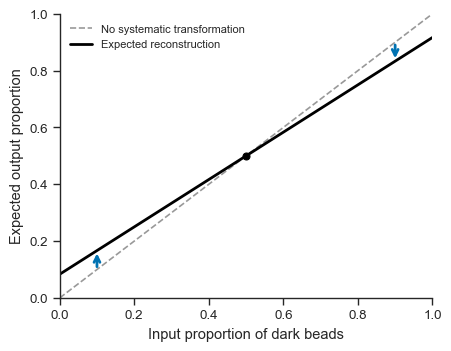

In [70]:
input_k = np.arange(n + 1) / n
mean_output = (np.arange(n + 1) + alpha) / (n + 2 * alpha)

fig, ax = plt.subplots(figsize=(4.4, 3.4), constrained_layout=True)
ax.plot([0, 1], [0, 1], "--", color="0.6", label="No systematic transformation")
ax.plot(input_k, mean_output, color="black", linewidth=2,
        label="Expected reconstruction")
for x in [0.1, 0.9]:
    observed = int(round(n * x))
    x = observed / n
    y = mean_output[observed]
    ax.annotate("", xy=(x, y), xytext=(x, x),
                arrowprops={"arrowstyle": "->", "color": "#0072B2", "lw": 2})
ax.scatter([0.5], [0.5], color="black", s=25, zorder=3)
ax.set(xlabel="Input proportion of dark beads", ylabel="Expected output proportion",
       xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()

## 3. Repeat along a chain

The model takes `n` (observations) and `alpha` (regularisation). It builds the symmetric Beta prior internally. Each learner uses the conjugate Beta posterior introduced above, samples `theta`, and produces the next `k`.

The following are starting conditions and simulation controls, rather than extra learning parameters:

| Control | Meaning |
|---|---|
| `k` | Starting dark-bead count; defaults to `n//2`. Each run resets to this value. |
| `N` | Number of learners in a chain; default 30. Generation 0 is the starting pattern. |
| `r_max` | Number of independent runs; default 1,000. |
| `seed` | Makes the random draws reproducible; default 7. |

`k_runs` stores counts: rows are generations and columns are runs. `r` counts runs; `t` counts learners. `k_initial` remembers the starting input. `a` and `b` are the posterior's two shape parameters, calculated from `k`, `n`, and `alpha`.

**TODOs 2–3:** sample `theta` from `Beta(a, b)`, then generate the next `k`.

In [71]:
def iterated_learning(n=10, alpha=5, *, k=None, N=30, r_max=1000, seed=7):
    rng = np.random.default_rng(seed)
    k_initial = n // 2 if k is None else k
    k_runs = np.zeros((N + 1, r_max), dtype=int)
    k_runs[0] = k_initial

    for r in range(r_max):
        k = k_initial
        for t in range(N):
            # Conjugate shortcut: exact Beta posterior for this learner.
            a = k + alpha
            b = n - k + alpha
            theta = rng.beta(a, b)
            k = rng.binomial(n, theta)
            k_runs[t + 1, r] = k
    return k_runs

## 4. Different inputs, the same prior

Start with 0, 5, or 10 dark beads. For each starting pattern, repeat the chain `r_max` times. Keep the prior unchanged so that only the initial input differs.

`results[start]` stores all runs for that starting count. First, draw one possible history: filled circles are dark beads and open circles are light beads. Their order is only for illustration.

In [78]:
n = 10
alpha = 0.0001
N = 30
r_max = 1000
starting_counts = [0, n // 2, n]
colors = ["#0072B2", "0.45", "#D55E00"]

results = {}
for i, start in enumerate(starting_counts):
    results[start] = iterated_learning(
        n=n, alpha=alpha, k=start, N=N,
        r_max=r_max, seed=7 + i)

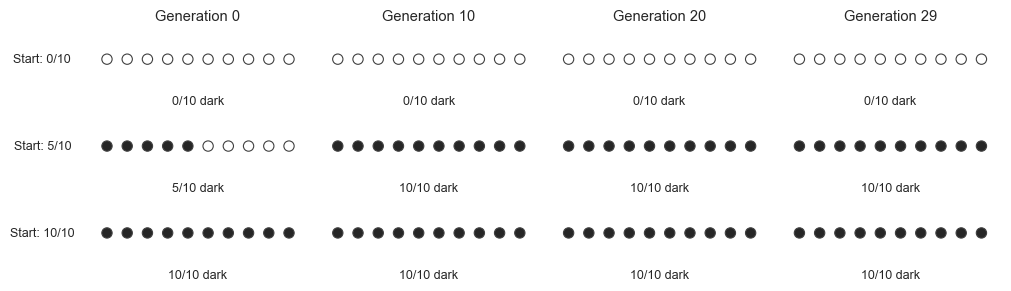

In [79]:
shown_N = np.unique(np.minimum([0, 10, 20, 29], N))
fig, axes = plt.subplots(3, len(shown_N), figsize=(10, 2.8),
                         squeeze=False, constrained_layout=True)
for row, start in enumerate(starting_counts):
    for col, t in enumerate(shown_N):
        ax = axes[row, col]
        dark = results[start][t, 0]
        bead_colors = np.where(np.arange(n) < dark, "0.15", "white")
        ax.scatter(np.arange(n), np.zeros(n), c=bead_colors,
                   edgecolors="0.25", s=55)
        ax.set(xlim=(-1, n), ylim=(-0.8, 0.8), xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_xlabel(f"{dark}/{n} dark", fontsize=9)
        if row == 0:
            ax.set_title(f"Generation {t}")
        if col == 0:
            ax.set_ylabel(f"Start: {start}/{n}", rotation=0, labelpad=32,
                          va="center", fontsize=9)
plt.show()

Next, average across runs. Pale lines show five individual runs; thick lines show the mean. The means approach 0.5 even though the starting patterns differ. Individual runs keep fluctuating.

A mean alone can hide different outcomes. We compare the full distributions next.

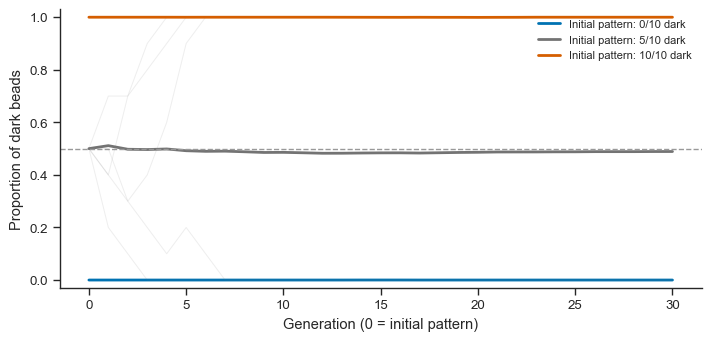

In [80]:
time = np.arange(N + 1)
fig, ax = plt.subplots(figsize=(7, 3.3), constrained_layout=True)
for start, color in zip(starting_counts, colors):
    counts = results[start]
    ax.plot(time, counts[:, :5] / n, color=color, alpha=0.12, linewidth=0.7)
    ax.plot(time, counts.mean(axis=1) / n, color=color, linewidth=2,
            label=f"Initial pattern: {start}/{n} dark")
ax.axhline(0.5, color="0.6", linestyle="--", linewidth=1)
ax.set(xlabel="Generation (0 = initial pattern)",
       ylabel="Proportion of dark beads", ylim=(-0.03, 1.03))
ax.legend(frameon=False, fontsize=8, loc="upper right")
plt.show()

## 5. Plot histograms of the final patterns

`plot_histograms(results, n, alpha)` is separate from the model. Each panel shows the final dark-bead counts for one starting input. Bar heights are fractions of runs.

The black reference is the count distribution predicted by the Beta prior. SciPy calculates it exactly with `betabinom.pmf`, the beta-binomial distribution. This converts a prior over `theta` into probabilities of bead counts, so the comparison uses the same scale.

Different starting inputs approach the same distribution after enough learners. Each learner still responds to the immediately preceding pattern.

In [81]:
def plot_histograms(results, n, alpha):
    possible_k = np.arange(n + 1)
    prior_k = betabinom.pmf(possible_k, n, alpha, alpha)
    bins = np.arange(n + 2) - 0.5
    fig, axes = plt.subplots(1, len(results), figsize=(9, 3),
                             sharex=True, sharey=True, constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, (start, runs) in zip(axes, results.items()):
        final = runs[-1]
        ax.hist(final, bins=bins, weights=np.ones(final.size) / final.size,
                color="0.8", edgecolor="white", label="Final generation")
        ax.plot(possible_k, prior_k, "o-", color="black", markersize=3,
                label="Beta prior prediction")
        ax.set(title=f"Started at {start}/{n} dark", xlabel="Dark-bead count, k",
               xticks=np.unique(np.linspace(0, n, min(n + 1, 6), dtype=int)))
    axes[0].set_ylabel("Fraction of runs")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.02),
               ncol=2, frameon=False)
    return fig, axes

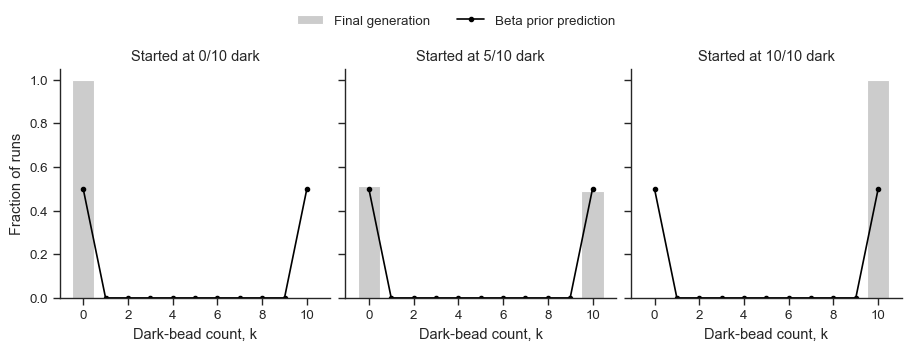

In [82]:
fig, axes = plot_histograms(results, n, alpha)
plt.show()

## 6. Compare three regularisation values

Keep `n` unchanged and start every chain at `k=n//2`. Compare Mesoudi's Beta priors with `alpha=0.1`, `1`, and `5`.

The top row shows each Beta density. Below, each heatmap row shows the distribution of `k` across repeated runs for one generation. Generation 1 is at the top. Brighter cells mean a larger fraction of runs; all heatmaps use the same colour scale.

`N_heatmap` is the number of learners per chain; `r_heatmap` is the number of repeated runs. `alphas` holds the three regularisation values; `heatmaps` holds their output frequencies. The plotting grid avoids exactly 0 and 1 because the Beta density diverges there when `alpha < 1`; the simulation samples from the continuous Beta distribution.

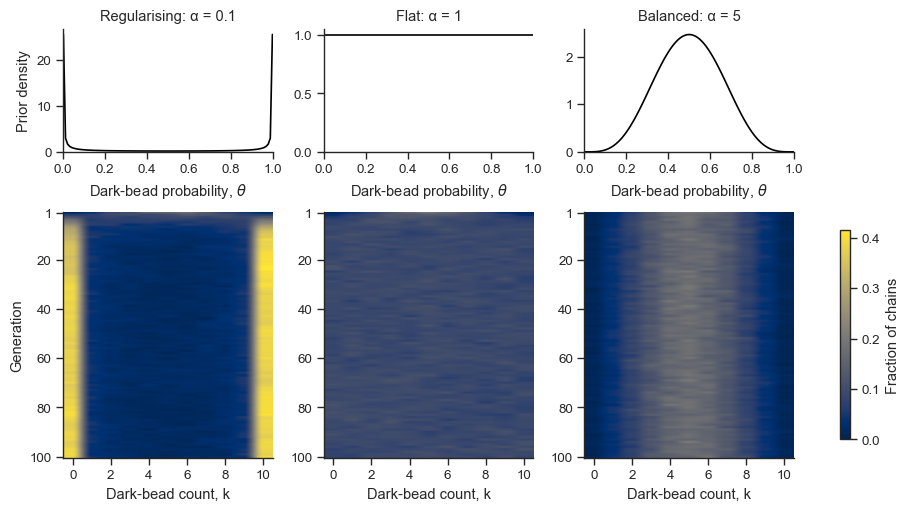

In [83]:
N_heatmap = 100
r_heatmap = 1000
alphas = {
    "Regularising: α = 0.1": 0.1,
    "Flat: α = 1": 1,
    "Balanced: α = 5": 5,
}
prior_curves = {}
heatmaps = {}
for i, (name, a) in enumerate(alphas.items()):
    prior_curves[name] = beta.pdf(p, a, a)
    chains = iterated_learning(
        n=n, alpha=a, k=n // 2,
        N=N_heatmap, r_max=r_heatmap, seed=30 + i)
    heatmaps[name] = np.array([
        np.bincount(row, minlength=n + 1) / r_heatmap for row in chains[1:]
    ])

fig, axes = plt.subplots(2, 3, figsize=(9, 5), constrained_layout=True,
                         gridspec_kw={"height_ratios": [1, 2]})
vmax = max(frequency.max() for frequency in heatmaps.values())
for col, name in enumerate(alphas):
    axes[0, col].plot(p, prior_curves[name], color="black")
    axes[0, col].set(title=name, xlabel=r"Dark-bead probability, $\theta$",
                     xlim=(0, 1), ylim=(0, None))
    image = axes[1, col].imshow(
        heatmaps[name], aspect="auto", cmap="cividis", vmin=0, vmax=vmax,
        extent=(-0.5, n + 0.5, N_heatmap + 0.5, 0.5))
    axes[1, col].set(xlabel="Dark-bead count, k",
                     xticks=np.unique(np.linspace(0, n, min(n + 1, 6), dtype=int)),
                     yticks=np.unique(np.linspace(1, N_heatmap, 6, dtype=int)))
axes[0, 0].set_ylabel("Prior density")
axes[1, 0].set_ylabel("Generation")
fig.colorbar(image, ax=axes[1, :], label="Fraction of chains", shrink=0.85)
plt.show()